# Original analysis — portable execution snapshot
Source: `original_exports/01_prepare_smard.ipynb`, received on 2026-11-07. Results below were executed by the user in Fabric before refactoring. They are not fresh executions of notebooks 01–04. Fabric-only table widgets have been converted to standard HTML/text without changing their values; the Matplotlib PNG is preserved byte for byte.

This snapshot retains the original query against `gold.dim_time_hour`; the runnable refactored analysis reads `silver.dim_time_hour`. Source data: Bundesnetzagentur | SMARD.de, CC BY 4.0.

In [8]:
spark.table("gold.dim_time_hour").createOrReplaceTempView("time_hour")

monthly_price_profile = spark.sql("""
    SELECT
        DATE_FORMAT(t.local_date, 'yyyy-MM') AS month,
        COUNT(*) AS matched_hours,
        ROUND(SUM(c.grid_load_mwh) / 1000000, 3)
            AS consumption_twh,
        ROUND(AVG(p.day_ahead_price_eur_mwh), 2)
            AS average_price_eur_mwh,
        ROUND(
            SUM(
                p.day_ahead_price_eur_mwh * c.grid_load_mwh
            ) / SUM(c.grid_load_mwh),
            2
        ) AS load_weighted_price_eur_mwh
    FROM silver.consumption_hour AS c
    INNER JOIN silver.price_hour AS p
        ON c.time_key = p.time_key
    INNER JOIN time_hour AS t
        ON c.time_key = t.time_key
    WHERE c.country_code = 'DE'
        AND p.bidding_zone_code = 'DE-LU'
    GROUP BY DATE_FORMAT(t.local_date, 'yyyy-MM')
    ORDER BY month
""")

display(monthly_price_profile)

month,matched_hours,consumption_twh,average_price_eur_mwh,load_weighted_price_eur_mwh
2025-01,744,44.171,114.14,118.49
2025-02,672,40.067,128.52,130.84
2025-03,743,40.564,94.73,96.82
2025-04,720,36.342,77.94,79.14
2025-05,744,36.265,67.34,67.48
2025-06,720,35.278,63.99,63.60
2025-07,744,37.036,87.80,87.72
2025-08,744,35.373,76.99,77.56
2025-09,720,36.472,83.51,85.26
2025-10,745,40.476,84.40,87.39


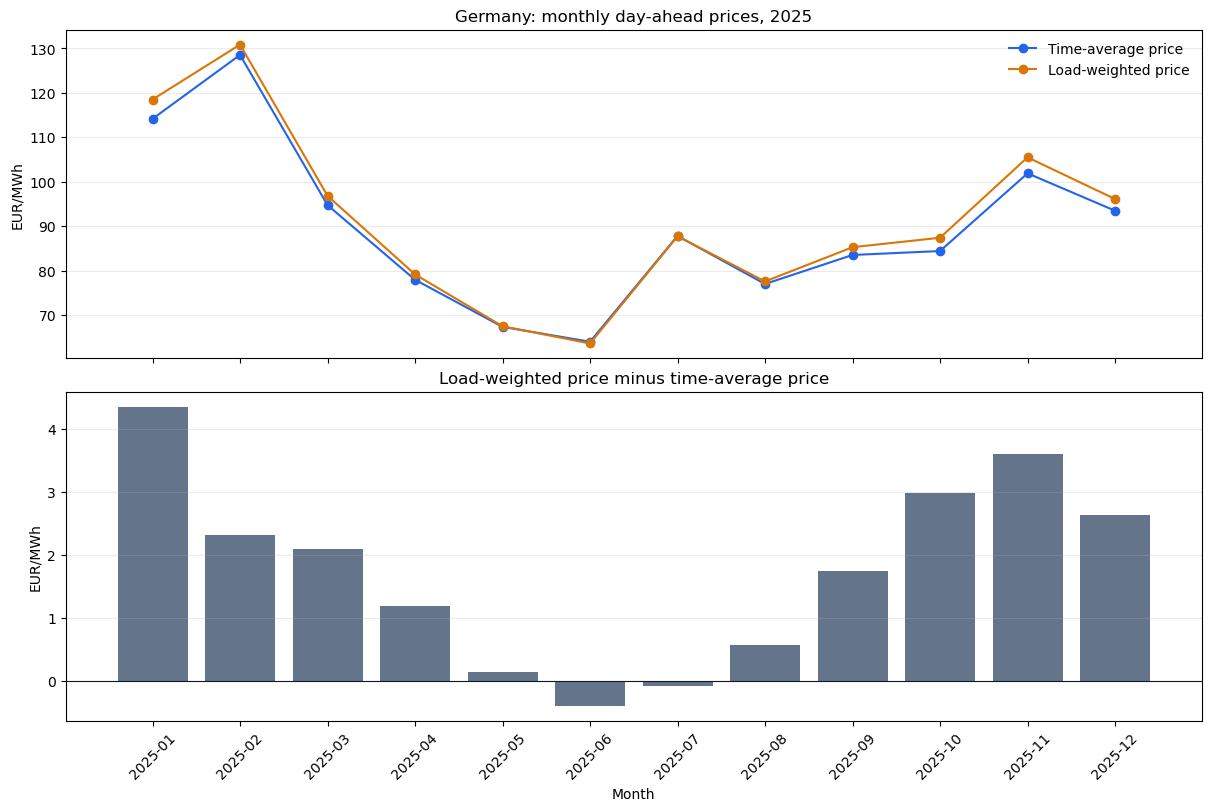

In [9]:
import matplotlib.pyplot as plt

monthly = monthly_price_profile.orderBy("month").toPandas()

price_columns = [
    "average_price_eur_mwh",
    "load_weighted_price_eur_mwh",
]

for column in price_columns:
    monthly[column] = monthly[column].astype(float)

monthly["price_gap_eur_mwh"] = (
    monthly["load_weighted_price_eur_mwh"]
    - monthly["average_price_eur_mwh"]
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True,
)

axes[0].plot(
    monthly["month"],
    monthly["average_price_eur_mwh"],
    marker="o",
    label="Time-average price",
    color="#2563EB",
)

axes[0].plot(
    monthly["month"],
    monthly["load_weighted_price_eur_mwh"],
    marker="o",
    label="Load-weighted price",
    color="#D97706",
)

axes[0].set_title("Germany: monthly day-ahead prices, 2025")
axes[0].set_ylabel("EUR/MWh")
axes[0].legend(frameon=False)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(
    monthly["month"],
    monthly["price_gap_eur_mwh"],
    color="#64748B",
)

axes[1].axhline(0, color="#111827", linewidth=0.8)
axes[1].set_title("Load-weighted price minus time-average price")
axes[1].set_ylabel("EUR/MWh")
axes[1].set_xlabel("Month")
axes[1].grid(axis="y", alpha=0.25)
axes[1].tick_params(axis="x", rotation=45)

plt.show()